# **Project : Binary Classification on ‘Customer_Churn’using Keras**
# **Problem Statement:**
You are the Data Scientist at a telecom company “Leo” whose customers are churning out to its
competitors. You have to analyse the data of your company and find insights and stop your customers from
churning out to other telecom companies.

# **Customer_churn Dataset:**
The details regarding this ‘customer_churn’ dataset are present in the data dictionary:

**Domain** –Telecom
**Domain Context** –
Customer churn, in simple terms means that the customer has stopped doing business with the company
and this is a common problem when it comes to telecom industries. To avoid this, companies use predictive
analysis to gauge the factors responsible for a customer to leave the company. These churn prediction
models help in finding out the customer base that are most likely to churn out.

**Lab Environment:** Google Colab
# **Tasks to be done:**
**A) Data Manipulation:**
a. Find the total number of male customers
b. Find the total number of customers whose Internet Service is ‘DSL’
c. Extract all the Female senior citizens whose Payment Method is Mailed check & store the
result in ‘new_customer’
d. Extract all those customers whose tenure is less than 10 months or their Total charges is less
than 500$ & store the result in ‘new_customer’

**B) Data Visualization:**
a. Build a pie-chart to show the distribution of customers would be churning out
b. Build a bar-plot to show the distribution of ‘Internet Service’

**C) Model Building:**
a. Build a sequential model using Keras, to find out if the customerwouldchurn or not, using
‘tenure’ as the feature and ‘Churn’ as the dependent/target column:

i. The visible/input layer should have 12 nodes with ‘Relu’ as activation function.

ii. This model would have 1 hidden layer with 8 nodes and ‘Relu’ as activation function

iii. Use ‘Adam’ as the optimization algorithm

iv. Fit the model on the train set, with number of epochs to be 150

v. Predict the values on the test set and build a confusion matrix

vi. Plot the ‘Accuracy vs Epochs’ graph

# **Build the 2nd model using same target and feature variables:**
i. Add a drop-out layer after the input layer with drop-out value of 0.3

ii. Add a drop-out layer after the hidden layer with drop-out value of 0.2

iii. Predict the values on the test set and build a confusion matrix

iv. Plot the ‘Accuracy vs Epochs’ graph

# **Build the 3rd model using ‘Tenure’, ’Monthly Charges’ & ‘Total Charges’ as the features and ‘Churn’ as the dependent/target column:**
i. The visible/input layer should have 12 nodes with ‘Relu’ as activation function.

ii. This model would have 1 hidden layer with 8 nodes and ‘Relu’ as activation function

iii. Use ‘Adam’ as the optimization algorithm

iv. Fit the model on the train set, with number of epochs to be 150

v. Predict the values on the test set and build a confusion matrix

vi. Plot the ‘Accuracy vs Epochs’ graph

TASK: Binary Classification using Keras


A) Data Manipulation

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.metrics import confusion_matrix

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# 1. Total male customers
male_count = df[df['gender'] == 'Male'].shape[0]
print(f"Total Male Customers: {male_count}")

# 2. Internet Service 'DSL'
dsl_count = df[df['InternetService'] == 'DSL'].shape[0]
print(f"Customers with DSL: {dsl_count}")

# 3. Female senior citizens with Mailed check
new_customer = df[(df['gender'] == 'Female') & (df['SeniorCitizen'] == 1) & (df['PaymentMethod'] == 'Mailed check')]

# 4. Tenure < 10 or TotalCharges < 500
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
new_customer_2 = df[(df['tenure'] < 10) | (df['TotalCharges'] < 500)]

Total Male Customers: 3555
Customers with DSL: 2421


B) Data Visualization

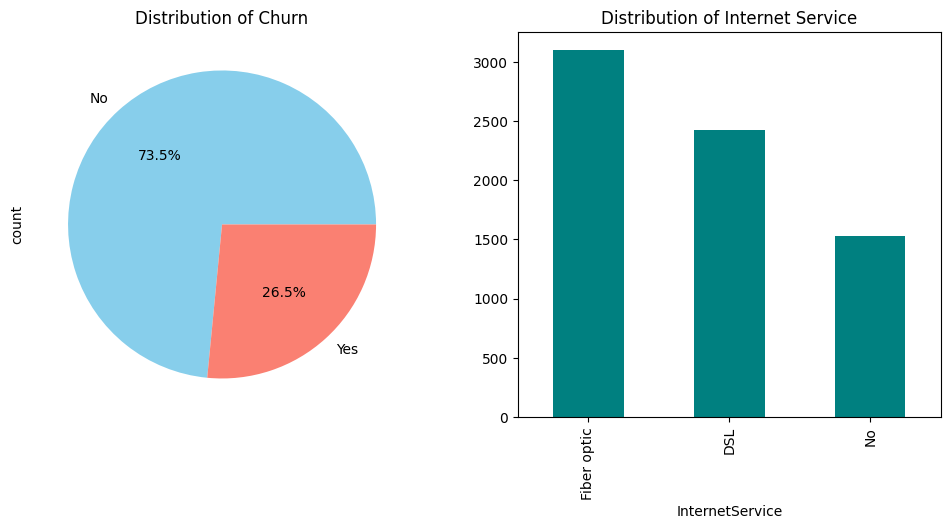

In [15]:
plt.figure(figsize=(12, 5))

# 1. Churn Distribution Pie Chart
plt.subplot(1, 2, 1)
df['Churn'].value_counts().plot.pie(autopct='%1.1f%%', colors=['skyblue', 'salmon'])
plt.title('Distribution of Churn')

# 2. Internet Service Bar Plot
plt.subplot(1, 2, 2)
df['InternetService'].value_counts().plot.bar(color='teal')
plt.title('Distribution of Internet Service')

plt.show()

C) Model Building

Model 1 : Single Feature (Tenure)

In [37]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
X = df[['tenure']]
y = df['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model1 = Sequential([
    Dense(12, activation='relu', input_shape=(1,)),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])
model1.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("Model 1 Architecture:")
model1.summary()

Model 1 Architecture:


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_33 (Dense)                │ (None, 12)             │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 137 (548.00 B)

 Trainable params: 137 (548.00 B)

 Non-trainable params: 0 (0.00 B)

In [38]:
history1 = model1.fit(
    X_train,
    y_train,
    epochs=150,
    verbose=1
)

Epoch 1/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7471 - loss: 0.6906
Epoch 2/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7522 - loss: 0.5157
Epoch 3/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7543 - loss: 0.5152
Epoch 4/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7542 - loss: 0.5155
Epoch 5/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7504 - loss: 0.5151
Epoch 6/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7460 - loss: 0.5148
Epoch 7/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7391 - loss: 0.5149
Epoch 8/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7386 - loss: 0.5155
Epoch 9/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7327 - loss: 0.5146
Epoch 10/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7341 - loss: 0.5167
Epoch 11/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7338 - loss: 0.5179
Epoch 12/150
177/177 ━━━━━━━━━━━━━━━━━━━━

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


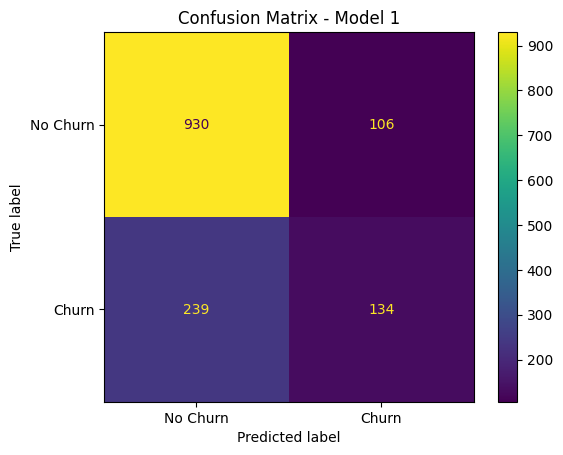

In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred1 = model1.predict(X_test)
y_pred1 = (y_pred1 >= 0.5).astype(int)

cm1 = confusion_matrix(y_test, y_pred1)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm1,
    display_labels=['No Churn', 'Churn']
)

disp.plot()
plt.title('Confusion Matrix - Model 1')
plt.show()

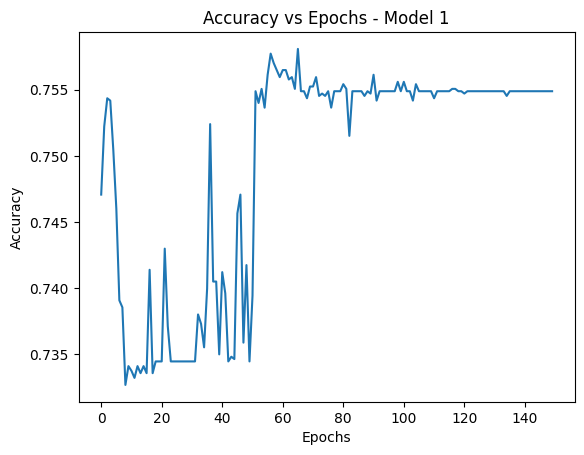

In [41]:
plt.plot(history1.history['accuracy'])

plt.title('Accuracy vs Epochs - Model 1')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

Model 2 : With Dropout Layers

In [42]:
model2 = Sequential([
    Dense(12, activation='relu', input_shape=(1,)),
    Dropout(0.3),
    Dense(8, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])
model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("Model 2 Architecture (with Dropout):")
model2.summary()

Model 2 Architecture (with Dropout):


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_36 (Dense)                │ (None, 12)             │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 137 (548.00 B)

 Trainable params: 137 (548.00 B)

 Non-trainable params: 0 (0.00 B)

In [43]:
history2 = model2.fit(
    X_train,
    y_train,
    epochs=150,
    verbose=1
)

Epoch 1/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6434 - loss: 1.7786
Epoch 2/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7061 - loss: 0.8712
Epoch 3/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7073 - loss: 0.7304
Epoch 4/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7160 - loss: 0.6719
Epoch 5/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7213 - loss: 0.6104
Epoch 6/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7204 - loss: 0.5957
Epoch 7/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7259 - loss: 0.5772
Epoch 8/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7277 - loss: 0.5547
Epoch 9/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7283 - loss: 0.5505
Epoch 10/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7288 - loss: 0.5537
Epoch 11/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7293 - loss: 0.5474
Epoch 12/150
177/177 ━━━━━━━━━━━━━━━━━━━━

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


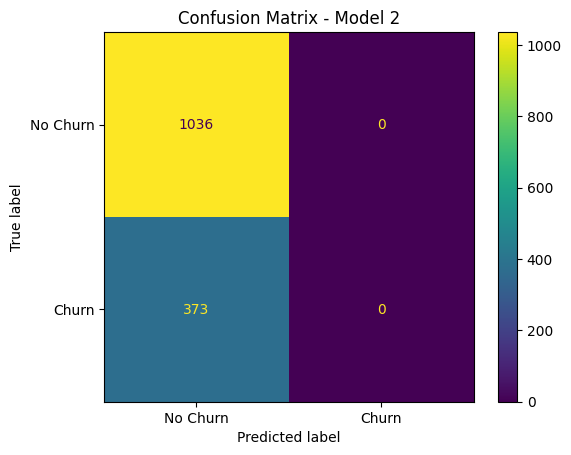

In [44]:
y_pred2 = model2.predict(X_test)

y_pred2 = (y_pred2 >= 0.5).astype(int)

cm2 = confusion_matrix(y_test, y_pred2)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm2,
    display_labels=['No Churn', 'Churn']
)

disp.plot()
plt.title('Confusion Matrix - Model 2')
plt.show()

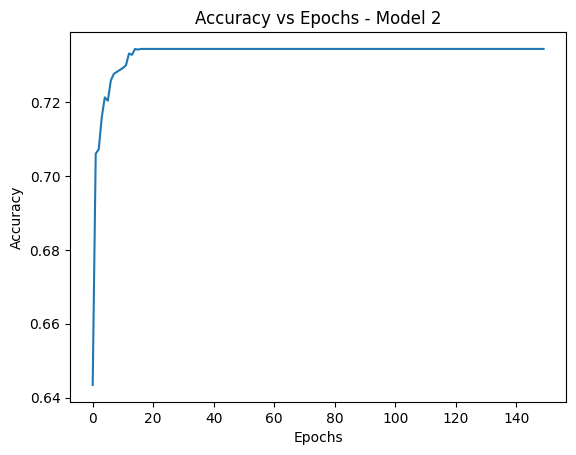

In [45]:
plt.plot(history2.history['accuracy'])

plt.title('Accuracy vs Epochs - Model 2')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

Model 3: Multi-Feature (Tenure, Monthly Charges, Total Charges)

In [57]:
X_multi = df[['tenure', 'MonthlyCharges', 'TotalCharges']].fillna(0)
X_train3, X_test3, y_train3, y_test3 = train_test_split(X_multi, y, test_size=0.2, random_state=42)

model3 = Sequential([
    Dense(12, activation='relu', input_shape=(3,)),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])
model3.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("Model 3 Architecture (Multi-feature):")
model3.summary()

Model 3 Architecture (Multi-feature):


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_48 (Dense)                │ (None, 12)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161 (644.00 B)

 Trainable params: 161 (644.00 B)

 Non-trainable params: 0 (0.00 B)

In [58]:
history3 = model3.fit(
    X_train3,
    y_train3,
    epochs=150,
    verbose=1
)

Epoch 1/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5007 - loss: 13.3111
Epoch 2/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5692 - loss: 0.8360
Epoch 3/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7584 - loss: 0.5656
Epoch 4/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7588 - loss: 0.5766
Epoch 5/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7483 - loss: 0.6003
Epoch 6/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7549 - loss: 0.5667
Epoch 7/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7579 - loss: 0.5446
Epoch 8/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7469 - loss: 0.6130
Epoch 9/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7492 - loss: 0.6327
Epoch 10/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7652 - loss: 0.5688
Epoch 11/150
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7551 - loss: 0.6144
Epoch 12/150
177/177 ━━━━━━━━━━━━━━━━━━━

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


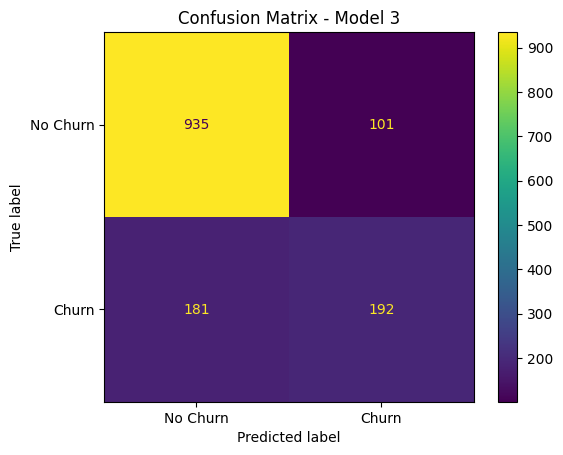

In [59]:
y_pred3 = model3.predict(X_test3)

y_pred3 = (y_pred3 >= 0.5).astype(int)

cm3 = confusion_matrix(y_test3, y_pred3)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm3,
    display_labels=['No Churn', 'Churn']
)

disp.plot()
plt.title('Confusion Matrix - Model 3')
plt.show()

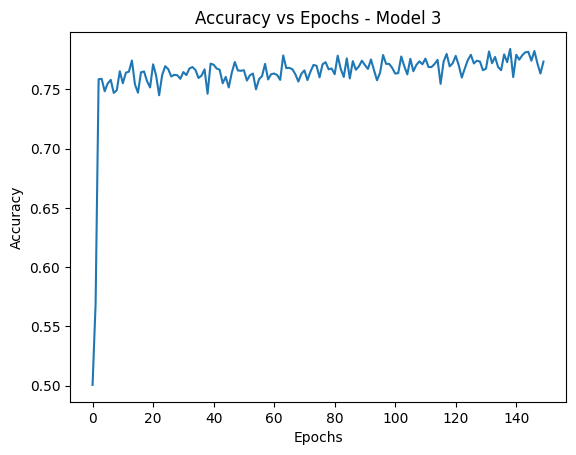

In [60]:
plt.plot(history3.history['accuracy'])

plt.title('Accuracy vs Epochs - Model 3')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()